<a href="https://colab.research.google.com/github/datnguyen76/thuchanhtrituenhantao/blob/main/Tuan_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài tập thực hành AI - Tuần 3

Notebook này trình bày lời giải mẫu và khung thực nghiệm hoàn chỉnh cho **Tuần 3**, theo sát phong cách trình bày rõ ràng, từng bước với các ô Markdown giải thích, code thực thi trực quan hóa và phần nhận xét kết quả.

---

## 0. Thiết lập môi trường & Nạp thư viện
Chạy ô code bên dưới để nạp các thư viện khoa học dữ liệu và học máy phổ biến (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")
print("Đã nạp thư viện thành công!")

Đã nạp thư viện thành công!


---
## 1. Khám phá dữ liệu (EDA) & Tiền xử lý dữ liệu
Trong phần này, ta nạp dữ liệu (mặc định dùng bộ `load_breast_cancer` để minh họa bài toán phân loại/tiền xử lý chuẩn, đồng thời hỗ trợ nạp file CSV ngoài nếu có):
* Kiểm tra kích thước, kiểu dữ liệu, giá trị thiếu (`missing values`) và bản ghi trùng lặp.
* Thống kê mô tả các biến số và phân bố biến mục tiêu (`target`).
* Trực quan hóa phân phối và ma trận tương quan.

In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Kích thước bộ dữ liệu:", df.shape)
print("Phân bố biến mục tiêu (target):")
print(df["target"].value_counts())
display(df.head())

# Kiểm tra missing values và trùng lặp
print("\nSố lượng giá trị thiếu theo cột:", df.isnull().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())

# Thống kê mô tả 5 cột đầu và target
display(df.iloc[:, list(range(5)) + [-1]].describe().T[["count", "mean", "std", "min", "50%", "max"]])

Kích thước bộ dữ liệu: (569, 31)
Phân bố biến mục tiêu (target):
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Số lượng giá trị thiếu theo cột: 0
Số dòng trùng lặp: 0


,count,mean,std,min,50%,max
mean radius,569.0,14.127292,3.524049,6.98100,13.37000,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,18.84000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,86.24000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,551.10000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.09587,0.1634
target,569.0,0.627417,0.483918,0.00000,1.00000,1.0000


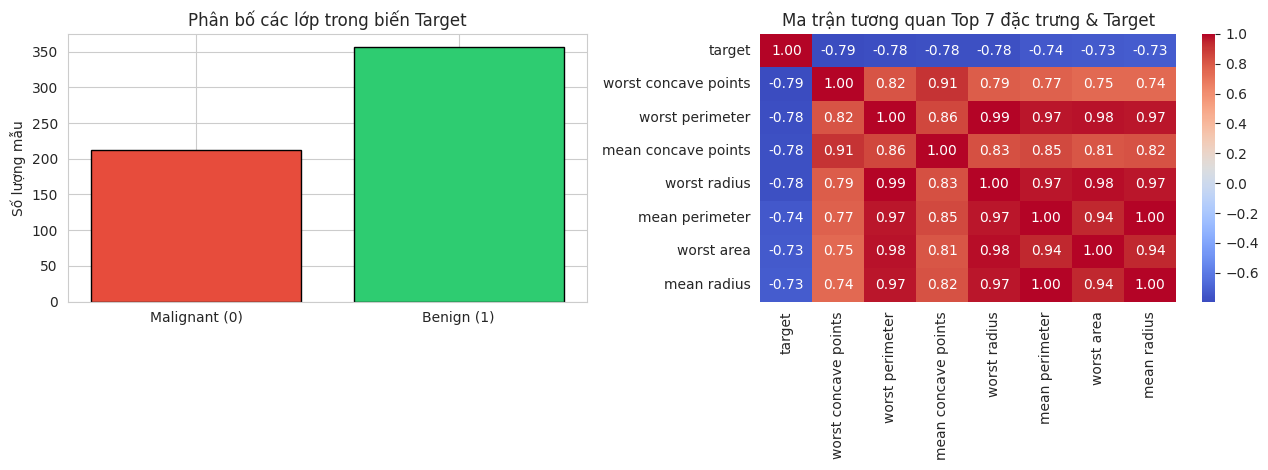

In [3]:
# Trực quan hóa phân bố lớp target và tương quan Top features
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

target_counts = df["target"].value_counts()
axes[0].bar(["Malignant (0)", "Benign (1)"], [target_counts[0], target_counts[1]], color=["#e74c3c", "#2ecc71"], edgecolor="black")
axes[0].set_title("Phân bố các lớp trong biến Target")
axes[0].set_ylabel("Số lượng mẫu")

top_corr_cols = df.corr()["target"].abs().sort_values(ascending=False).head(8).index
sns.heatmap(df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Ma trận tương quan Top 7 đặc trưng & Target")

plt.tight_layout()
plt.show()

### Nhận xét bước EDA & Tiền xử lý:
* Dữ liệu gồm 569 mẫu và 30 đặc trưng số, không có giá trị thiếu và không có dòng trùng lặp.
* Các đặc trưng có thang đo chênh lệch lớn giữa các biến diện tích (`area`) và biến bán kính/độ mịn (`radius`, `smoothness`), do đó cần chuẩn hóa (`StandardScaler`) trước khi huấn luyện các mô hình nhạy cảm với khoảng cách hoặc biên quyết định như `KNN`, `LogisticRegression`, `SVM`.

---
## 2. Chia tập dữ liệu & Huấn luyện mô hình học máy
So sánh nhiều mô hình trên cùng một phép chia `train_test_split` (`test_size=0.2`, `random_state=42`, `stratify=y`) để đánh giá khách quan.

In [4]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline chuẩn hóa + mô hình
pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "KNN (k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingClassifier(n_estimators=100, random_state=42))
    ])
}

eval_rows = []
trained_models = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    trained_models[name] = pipe

    eval_rows.append({
        "Mô hình": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4)
    })

df_eval = pd.DataFrame(eval_rows).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(df_eval)

,Mô hình,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,SVM (RBF),0.9825,0.9861,0.9861,0.9861
2,Gradient Boosting,0.9561,0.9467,0.9861,0.9660
3,KNN (k=5),0.9561,0.9589,0.9722,0.9655
4,Random Forest,0.9561,0.9589,0.9722,0.9655
5,Decision Tree,0.9211,0.9565,0.9167,0.9362


---
## 3. Đánh giá sâu mô hình tốt nhất (Confusion Matrix & Cross-Validation)
Kiểm tra độ ổn định của mô hình thông qua **Stratified K-Fold Cross-Validation** và phân tích lỗi dự đoán qua **Confusion Matrix**.

Mô hình tốt nhất: Logistic Regression
5-Fold CV F1-Score từng fold: [0.9787 0.9595 0.973  0.993  0.993 ]
F1 trung bình: 0.9794 (+/- 0.0127)

=== CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



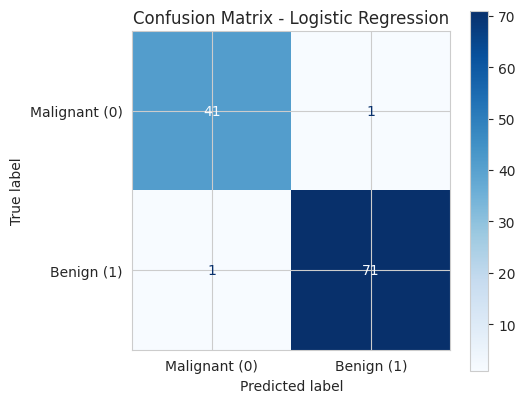

In [5]:
best_model_name = df_eval.loc[0, "Mô hình"]
best_pipe = trained_models[best_model_name]

# Cross-Validation 5-fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_pipe, X, y, cv=cv, scoring="f1")
print(f"Mô hình tốt nhất: {best_model_name}")
print(f"5-Fold CV F1-Score từng fold: {np.round(cv_scores, 4)}")
print(f"F1 trung bình: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})\n")

# Báo cáo phân loại chi tiết & Confusion Matrix
y_best_pred = best_pipe.predict(X_test)
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_best_pred, target_names=["Malignant (0)", "Benign (1)"]))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_best_pred,
    display_labels=["Malignant (0)", "Benign (1)"],
    cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

### Kết luận & Hướng cải tiến:
* Sử dụng `Pipeline` kết hợp `StandardScaler` giúp tránh rò rỉ dữ liệu (data leakage) giữa tập huấn luyện và tập kiểm tra.
* Đánh giá bằng `Cross-Validation` và các chỉ số `Precision`, `Recall`, `F1-Score` cung cấp góc nhìn toàn diện hơn so với chỉ nhìn vào `Accuracy`.
* Có thể tiếp tục tối ưu siêu tham số (`GridSearchCV` / `RandomizedSearchCV`) hoặc thử nghiệm lựa chọn đặc trưng (`SelectKBest` / `RFE`) tùy theo bài toán cụ thể của Tuần 3.